In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar
from scipy.special import logsumexp, gamma
from scipy.integrate import solve_ivp
from scipy.stats import poisson
from IPython.display import display, Math

In [14]:
def get_Gamma_s(Omega_p, Delta_p, g_s, kappa_s, N, m):
    prefactor = (Omega_p**2 * g_s**2) / (kappa_s * Delta_p**2)
    scaling = (N - m) * (m + 1)
    
    Gamma_s = prefactor * scaling
    
    return Gamma_s

def get_Gamma_as(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, m):
    
    delta_e = g_s**2 / Delta_p
    
    nom = m * (N - m + 1) * Omega_c**2 * g_as**2 * (get_Gamma_s(Omega_p, Delta_p, g_s, kappa_s, N, m-1) + kappa_as)
    denom = (Delta_c - delta_e)**2 * (get_Gamma_s(Omega_p, Delta_p, g_s, kappa_s, N, m-1) + kappa_as)**2 + 4 * (N - m + 1)**2 * g_as**4
    
    Gamma_as = nom / denom
    
    return Gamma_as

In [15]:
Omega_p = 1.0
Delta_p = 20.0
g_s = 1.0
g_as = 2.0
kappa_s = 50.0
kappa_as = 10.0
Delta_c = -g_s**2 / Delta_p

N = 2

Omega_c = 0.042416864150194425

print("Gamma_s:")
for m in np.arange(N+1):
    print(get_Gamma_s(Omega_p, Delta_p, g_s, kappa_s, N, m))
print("Gamma_as:")
for m in np.arange(N+1):
    print(get_Gamma_as(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, m))

Gamma_s:
0.0001
0.0001
0.0
Gamma_as:
0.0
0.0005600648143884167
0.0022144096032424908


In [16]:
def build_and_solve_detailed_balance_equation(Omega_p, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, bracket=[0.1, 10.0]):
    
    def objective(Omega_c):
            
        # m from 0 to N
        m_list = np.arange(N + 1)
            
        Gamma_s = get_Gamma_s(Omega_p, Delta_p, g_s, kappa_s, N, m_list)
        Gamma_as = get_Gamma_as(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, m_list)
    
        # be save of zero-division
        Gamma_s = np.clip(Gamma_s, 1e-3300, None)
        Gamma_as = np.clip(Gamma_as, 1e-300, None)

        # to be numerically more efficient, calculate all the weights in log-space
        log_W = np.zeros(N + 1)
        if N > 0:
            # use log-rules, which gives us a difference instead of a ratio
            log_ratios = np.log(Gamma_s[:-1]) - np.log(Gamma_as[1:])
            log_W[1:] = np.cumsum(log_ratios)
    
        log_denom = logsumexp(log_W)
        
        m_nonzero = m_list[1:]
        log_nom = logsumexp(np.log(m_nonzero) + log_W[1:])
        
        # change back to normal space by exponentiating
        mean_m = np.exp(log_nom - log_denom)
        
        return mean_m - (N / 2.0)
        
    # try to solve with root_scalar
    try:
        # find optimal Omega_c for half/half occupation
        result = root_scalar(objective, bracket=bracket, method="brentq")
        return result.root
    except ValueError as e:
        print(f"No solution found in interval: {e}")
        return None

In [163]:
# Omega_p = 1.0
# Delta_p = 20.0
# g_s = 1.0
# g_as = 1.0
# kappa_s = 10.0
# kappa_as = 10.0
# Delta_c = -g_s**2 / Delta_p

# N = 4

# Omega_p = 2.5
# Delta_p = 50.0
# g_s = 1.0
# g_as = 1.0
# kappa_s = 20.0
# kappa_as = 20.0
# Delta_c = g_s**2 / Delta_p

# optimal_Omega_c = 3.0

Omega_p = 0.9
Delta_p = 20.0
g_s = 1.0
g_as = 1.0
kappa_s = 20.0
kappa_as = 20.0
Delta_c = g_s**2 / Delta_p

optimal_Omega_c = 1.6

# optimal_Omega_c = build_and_solve_detailed_balance_equation(Omega_p, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, bracket=[0.001, 3.0]) 
print(optimal_Omega_c)

1.6


In [164]:
def calculate_propabilities(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N):
    
    m_list = np.arange(N + 1)
    
    Gamma_s = get_Gamma_s(Omega_p, Delta_p, g_s, kappa_s, N, m_list)
    Gamma_as = get_Gamma_as(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, m_list)
    
    Gamma_s = np.clip(Gamma_s, 1e-300, None)
    Gamma_as = np.clip(Gamma_as, 1e-300, None)
    
    W = np.ones(N + 1)
    if N > 0:
        W[1:] = np.cumprod(Gamma_s[:-1] / Gamma_as[1:])
        
    P_0 = 1.0 / np.sum(W)
        
    p_vec = P_0 * W
        
    return list(p_vec)    

In [165]:
possible_Omega_c = np.linspace(0, 3, 20)

for Omega_c in possible_Omega_c:
    display(Math(rf"$\Omega_\text{{c}} = {Omega_c:.2f}, \qquad P_1 = {calculate_propabilities(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N)[1]}, \qquad P_0 = {calculate_propabilities(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N)[0]}$"))

c:\Users\lauri\anaconda3\envs\thesis-simulation\Lib\site-packages\numpy\_core\fromnumeric.py:54: RuntimeWarning: overflow encountered in accumulate
  return bound(*args, **kwds)
C:\Users\lauri\AppData\Local\Temp\ipykernel_21336\1717840624.py:17: RuntimeWarning: invalid value encountered in multiply
  p_vec = P_0 * W


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

... (11 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [166]:
# solve the equation of motion for p_m

def simulate_time_evolution(Omega_p, optimal_Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, t_max=100.0):
    
    m_list = np.arange(N + 1)
    
    Gamma_s = get_Gamma_s(Omega_p, Delta_p, g_s, kappa_s, N, m_list)
    Gamma_as = get_Gamma_as(Omega_p, optimal_Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, m_list)
    
    Gamma_s_full = np.zeros(N + 1)
    Gamma_as_full = np.zeros(N + 1)
    Gamma_s_full[:-1] = Gamma_s[:-1]
    Gamma_as_full[1:] = Gamma_as[1:]
    
    # transition matrix
    M = np.zeros((N + 1, N + 1))
    
    for m in range(N + 1):
        loss = 0
        if m < N:
            loss += Gamma_s_full[m]
            M[m + 1, m] = Gamma_s_full[m]
        if m > 0:
            loss += Gamma_as_full[m]
            M[m - 1, m] = Gamma_as_full[m]
        M[m, m] = -loss
        
    # define the master equation
    def master_equation(t, P):
        return M @ P
    
    # initially start in |m=0>
    P_init = np.zeros(N + 1)
    P_init[0] = 1.0
    
    t_eval = np.linspace(0, t_max, 500)
    sol = solve_ivp(master_equation, [0, t_max], P_init, t_eval=t_eval, method="Radau")
    
    return sol.t, sol.y
    

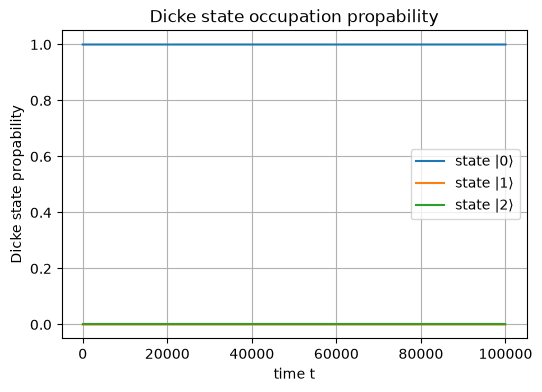

In [167]:
# plot the time evolution

time, dicke_propability = simulate_time_evolution(Omega_p, optimal_Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, t_max=100000.0)

plt.figure(figsize=(6, 4))

for m, data in enumerate(dicke_propability):
    plt.plot(time, data, label=rf"state $\vert {m} \rangle$")
    
plt.title("Dicke state occupation propability")
plt.xlabel("time t")
plt.ylabel("Dicke state propability")
plt.grid(True)
plt.legend()

plt.show()

In [ ]:
def run_gillespie_stokes_simulation(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, t_start=0.0, integration_time=100.0, num_trajectories=100):
    
    m_list = np.arange(N + 1)
    
    Gamma_s = get_Gamma_s(Omega_p, Delta_p, g_s, kappa_s, N, m_list)
    Gamma_as = get_Gamma_as(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, m_list)
    
    t_end = t_start + integration_time
    
    results = []
        
    for _ in range(num_trajectories):
        t = 0.0
        m = 0
        
        stokes_count = 0
        anti_stokes_count = 0
        
        while t < t_end:
            rate_up = Gamma_s[m] if m < N else 0.0
            rate_down = Gamma_as[m] if m > 0 else 0.0
            total_rate = rate_up + rate_down
            
            if total_rate <= 0.0:
                break
             
            tau = -np.log(np.random.uniform()) / total_rate
            t += tau
            
            if t > t_end:
                break
            
            r2 = np.random.uniform(0, total_rate)
            
            if r2 < rate_up:
                m += 1
                
                # only count events in the measurement window
                if t >= t_start:
                    stokes_count += 1
                    stokes_times.append(t)
            
            else:
                m -= 1
                
                # only count events in the measurement window
                if t >= t_start:
                    anti_stokes_count += 1
                                
        results.append((stokes_count, anti_stokes_count))
        
    return np.array(results)

In [169]:
def poissonian_statistics(n, mean_n):
    # normal poissonian: expectation value = variance
    return ((mean_n**n)/(gamma(n + 1))) * np.exp(-mean_n)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Fano factor: 0.99


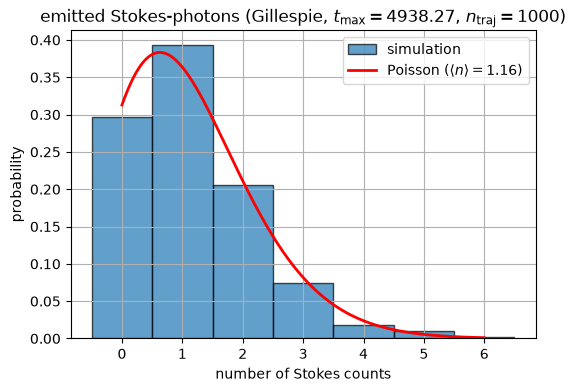

In [173]:
t_max = 1/get_Gamma_s(Omega_p, Delta_p, g_s, kappa_s, N, 0)
tau_s = 1/get_Gamma_s(Omega_p, Delta_p, g_s, kappa_s, N, 0)
two_tau_s = 2/get_Gamma_s(Omega_p, Delta_p, g_s, kappa_s, N, 0)
tau_as = 1/get_Gamma_as(Omega_p, optimal_Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, 1)

t_start = 5 * tau_s
integration_time = 1.2* tau_s
num_trajectories = 1000

display(Math(rf"$\tau_\text{{as}} = {tau_as:.2f}$"))
display(Math(rf"$\tau_\text{{s}} = {tau_s:.2f}$"))
display(Math(rf"$t_\text{{start}} = {t_start:.2f}$"))
display(Math(rf"$t_\text{{int}} = {integration_time:.2f}$"))

data = run_gillespie_stokes_simulation(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, t_start=t_start, integration_time=integration_time, num_trajectories=num_trajectories)

stokes_data = data[:, 0]
anti_stokes_data = data[:, 1]

min_val = int(min(stokes_data))
max_val = int(max(stokes_data))

n_cont = np.linspace(0, max_val, 1000)

bins = np.arange(min_val - 0.5, max_val + 1.5, 1)
mean = np.mean(stokes_data)
variance = np.var(stokes_data)

fano_factor = variance / mean

print(rf'Fano factor: {fano_factor:.2f}')

plt.figure(figsize=(6, 4))
plt.hist(stokes_data, bins=bins, density=True, edgecolor="black", alpha=0.7, label='simulation')
plt.plot(n_cont, poissonian_statistics(n_cont, mean), 'r-', linewidth=2, markersize=6, label=rf'Poisson ($\langle n \rangle = {mean:.2f}$)')
plt.title(rf"emitted Stokes-photons (Gillespie, $t_\text{{max}} = {t_max:.2f}$, $n_\text{{traj}} = {num_trajectories}$)")
plt.xlabel("number of Stokes counts")
plt.ylabel("probability")
plt.legend()
plt.grid(True)
plt.xticks(range(min_val, max_val + 1))

plt.show()

In [171]:
# data = run_gillespie_stokes_simulation(Omega_p, Omega_c, Delta_p, Delta_c, g_s, g_as, kappa_s, kappa_as, N, t_start=t_start, integration_time=integration_time, num_trajectories=5000)

# occupation_data = np.array([x[2] for x in data])
# mean_occupation = np.mean(occupation_data, axis=0)

# P0 = mean_occupation[0]
# P1 = mean_occupation[1]
# P_ge_2 = np.sum(mean_occupation[2:])

# print(f"P(m=0): {P0:.4f}")
# print(f"P(m=1): {P1:.4f}")
# print(f"P(m>=2): {P_ge_2:.4f}")
# print(f"Sum: {P0 + P1 + P_ge_2:.4f}")

In [26]:
import numpy as np
import matplotlib.pyplot as plt

t_start_values = np.linspace(0, 100, 50)
integration_times = np.linspace(1, 100, 50)

P0_map = np.zeros((len(integration_times), len(t_start_values)))
P1_map = np.zeros_like(P0_map)
Pge2_map = np.zeros_like(P0_map)

for i, T in enumerate(integration_times):
    for j, t_start in enumerate(t_start_values):

        data = run_gillespie_stokes_simulation(
            Omega_p, Omega_c,
            Delta_p, Delta_c,
            g_s, g_as,
            kappa_s, kappa_as,
            N,
            t_start=t_start,
            integration_time=T,
            num_trajectories=5000
        )

        occupation_data = np.array([x[2] for x in data])
        mean_occupation = np.mean(occupation_data, axis=0)

        P0_map[i, j] = mean_occupation[0]
        P1_map[i, j] = mean_occupation[1]
        Pge2_map[i, j] = np.sum(mean_occupation[2:])

IndexError: index 2 is out of bounds for axis 0 with size 2

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

data_maps = [
    (P0_map, r"$\bar{P}(m=0)$"),
    (P1_map, r"$\bar{P}(m=1)$"),
    (Pge2_map, r"$\bar{P}(m\geq 2)$")
]

for ax, (data, title) in zip(axes, data_maps):

    im = ax.imshow(
        data,
        origin="lower",
        aspect="auto",
        extent=[
            t_start_values[0],
            t_start_values[-1],
            integration_times[0],
            integration_times[-1]
        ],
        vmin=0,
        vmax=1
    )

    ax.set_xlabel(r"$t_\mathrm{start}$")
    ax.set_ylabel(r"$T$")
    ax.set_title(title)

    fig.colorbar(im, ax=ax, label="Occupation probability")

plt.tight_layout()
plt.show()